<a href="https://colab.research.google.com/github/ArtemFirst1/DataLoves_homework/blob/main/%22HW_2_1_%D0%90%D0%BD%D0%B0%D0%BB%D1%96%D0%B7_%D0%BE%D0%B7%D0%BD%D0%B0%D0%BA_%D0%B4%D0%BB%D1%8F_%D0%BF%D0%BE%D0%B1%D1%83%D0%B4%D0%BE%D0%B2%D0%B8_%D0%BB%D1%96%D0%BD%D1%96%D0%B8%CC%86%D0%BD%D0%BE%D1%97_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%97%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Завдання 1**: Завантажте дані `medical-charges.csv` в пандас датафрейм і виведіть перші 5 записів. Напишіть, як ви можете підійти до вирішення задачі прогнозування колонки `charges` на основі інших колонок виходячи з наявних на даний момент знань (без ML методів, чисто з використанням аналітики). Запишіть 3 або більше ідей, які приходять вам на думку нижче:

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt


In [ ]:
medical_df = pd.read_csv('/content/medical-charges.csv')
print('Кількість записів:', len(medical_df))
medical_df.head()

Кількість записів: 1338


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Ідеї**:
1. Розділити людей на вікові групи та порахувати середні витрати в кожній групі.
2. Окремо порівняти середні витрати курців і некурців та використовувати відповідне середнє для прогнозу.
3. Розділити людей за значенням BMI та порівняти витрати між групами.
4. Поєднати кілька ознак, наприклад вікову групу та статус куріння, і прогнозувати витрати за середнім значенням відповідної групи.

Виходжу виключно зі своїх знань в Клієнтській аналітиці)


**Завдання 2**: Візуалізуйте розподіл медичних зборів (`charges`) у вигляді інтерактивної гістограми plotly з розбиттями за категоріями ознак
1. `sex`
2. `region`

Додайте маржинальний графік у вигляді бокс-плота вгорі по дикретним категоріям ознак.
Скористайтесь прикладом візуалізації з лекції.
Опишіть свої спостереження.

In [ ]:
px.histogram(medical_df, x='charges', color='sex', marginal='box', barmode='overlay', opacity=0.6).show()
px.histogram(medical_df, x='charges', color='region', marginal='box', barmode='overlay', opacity=0.6).show()

print('Витрати за статтю:')
print(medical_df.groupby('sex')['charges'].agg(['mean', 'median']).round(2))
print('Витрати за регіонами:')
print(medical_df.groupby('region')['charges'].agg(['mean', 'median']).round(2))
print('Частка витрат до 20000:', round((medical_df['charges'] < 20000).mean() * 100, 2), '%')

Витрати за статтю:
            mean   median
sex                      
female  12569.58  9412.96
male    13956.75  9369.62
Витрати за регіонами:
               mean    median
region                       
northeast  13406.38  10057.65
northwest  12417.58   8965.80
southeast  14735.41   9294.13
southwest  12346.94   8798.59
Частка витрат до 20000: 79.6 %


**Висновок**: На графіках бачимо, що 79,6% людей мають медичні витрати до 20 000. Середні витрати чоловіків становлять 13 956,75, а жінок — 12 569,58, хоча медіанні значення майже однакові. Серед регіонів найбільші середні витрати спостерігаються у southeast, а найменші — у southwest. Загалом розподіли витрат за статтю та регіонами досить схожі, але відрізняються середніми значеннями.


**Завдання 3**: Візуалізуйте з `plotly` розподіл кожного з настуних стовпців відносно того, чи є людина курцем (`smoker`)
- `region`
- `children`

та опишіть коротко свої спостереження.

In [ ]:
px.histogram(medical_df, x='region', color='smoker', barmode='group').show()
px.histogram(medical_df, x='children', color='smoker', barmode='group').update_xaxes(dtick=1).show()

print('Загальна кількість людей:')
print(medical_df['smoker'].value_counts())

print('Кількість людей за регіонами:')
print(pd.crosstab(medical_df['region'], medical_df['smoker']))
print('Кількість людей за кількістю дітей:')
print(pd.crosstab(medical_df['children'], medical_df['smoker']))
print('Частка курців за регіонами, %:')
print((pd.crosstab(medical_df['region'], medical_df['smoker'], normalize='index')['yes'] * 100).round(2))
print('Частка курців за кількістю дітей, %:')
print((pd.crosstab(medical_df['children'], medical_df['smoker'], normalize='index')['yes'] * 100).round(2))

region_share = pd.crosstab(medical_df['region'], medical_df['smoker'], normalize='index')['yes'] * 100
print('Найбільша частка курців:', region_share.idxmax(), round(region_share.max(), 2), '%')

Загальна кількість людей:
smoker
no     1064
yes     274
Name: count, dtype: int64
Кількість людей за регіонами:
smoker      no  yes
region             
northeast  257   67
northwest  267   58
southeast  273   91
southwest  267   58
Кількість людей за кількістю дітей:
smoker     no  yes
children          
0         459  115
1         263   61
2         185   55
3         118   39
4          22    3
5          17    1
Частка курців за регіонами, %:
region
northeast    20.68
northwest    17.85
southeast    25.00
southwest    17.85
Name: yes, dtype: float64
Частка курців за кількістю дітей, %:
children
0    20.03
1    18.83
2    22.92
3    24.84
4    12.00
5     5.56
Name: yes, dtype: float64
Найбільша частка курців: southeast 25.0 %


**Висновок**: У нашому наборі даних значно більше некурців (1064), ніж курців (274). Найбільша частка курців спостерігається в регіоні southeast — 25%, а найменша — у northwest та southwest, по 17,85%. Якщо розглядати кількість дітей, то найбільша частка курців серед людей із трьома дітьми — 24,84%. Водночас чіткої залежності між кількістю дітей та курінням не спостерігається.

**Завдання 4**: Візуалізуйте звʼязок між стовпцем `charges` та `children` використовуючи графіки-скрипки (`px.violin`). Опишіть свої спостереження.

In [ ]:
px.violin(medical_df, x='children', y='charges', box=True, points='outliers').update_xaxes(dtick=1).show()
print(medical_df.groupby('children')['charges'].agg(['count', 'mean', 'median']).round(2))

children_mean = medical_df.groupby('children')['charges'].mean()
print('Найбільші середні витрати у групі з кількістю дітей:', children_mean.idxmax())
print('Середні витрати цієї групи:', round(children_mean.max(), 2))

          count      mean    median
children                           
0           574  12365.98   9856.95
1           324  12731.17   8483.87
2           240  15073.56   9264.98
3           157  15355.32  10600.55
4            25  13850.66  11033.66
5            18   8786.04   8589.57
Найбільші середні витрати у групі з кількістю дітей: 3
Середні витрати цієї групи: 15355.32


**Висновок**: За графіком та розрахунками бачимо, що середні медичні витрати поступово зростають у групах від 0 до 3 дітей. Найбільші середні витрати мають люди з трьома дітьми — 15 355,32, а найменші — з п'ятьма дітьми, 8 786,04. Проте у групах із чотирма та п'ятьма дітьми значно менше людей, ніж в інших групах. Тому не можна однозначно стверджувати, що зі збільшенням кількості дітей зростають медичні витрати.

**Завдання 5.** Розглянемо модель для користувачів, які не є курцями (`no_smoker_df`):

$$charges = w \times age + b$$

Спробуйте 3 різні пари параметрів `w` та `b` аби вручну підігнати лінію під дані використовуючи наведені допоміжні функції `estimate_charges` та `try_parameters`. Опишіть спостереження.
Пари параметрів мають бути НЕ такі, як були наведені в лекції.

In [ ]:
non_smoker_df = medical_df[medical_df.smoker == 'no']
print('Кількість некурців:', len(non_smoker_df))
print('Кореляція віку та витрат:', round(non_smoker_df['age'].corr(non_smoker_df['charges']), 2))

Кількість некурців: 1064
Кореляція віку та витрат: 0.63


In [ ]:
def estimate_charges(age, w, b):
    return w * age + b

In [ ]:
def try_parameters(df, w, b):
    ages = df.age
    target = df.charges

    estimated_charges = estimate_charges(ages, w, b)

    plt.plot(ages, estimated_charges, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8,alpha=0.8);
    plt.xlabel('Age');
    plt.ylabel('Charges')
    plt.legend(['Estimate', 'Actual']);

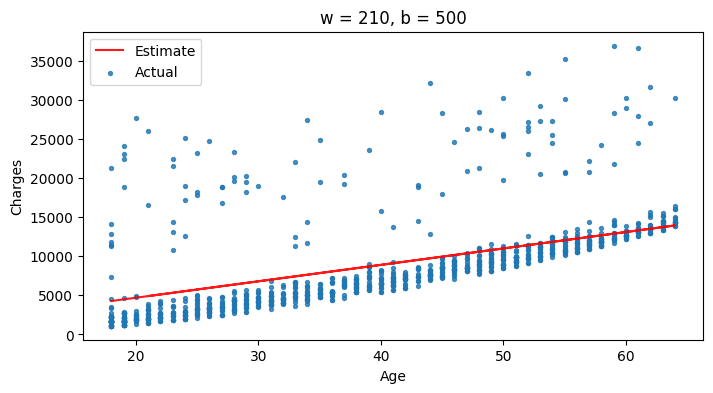

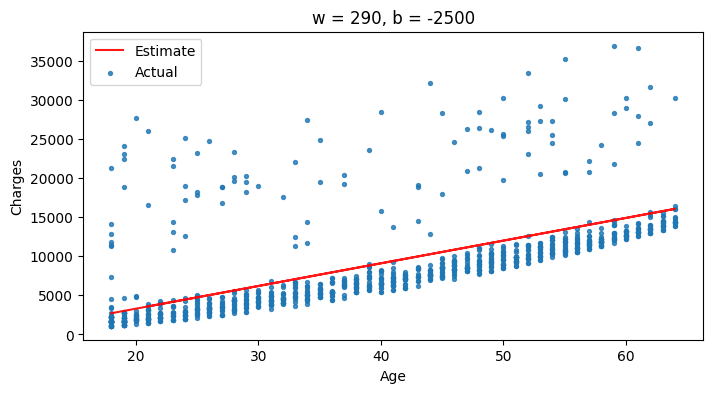

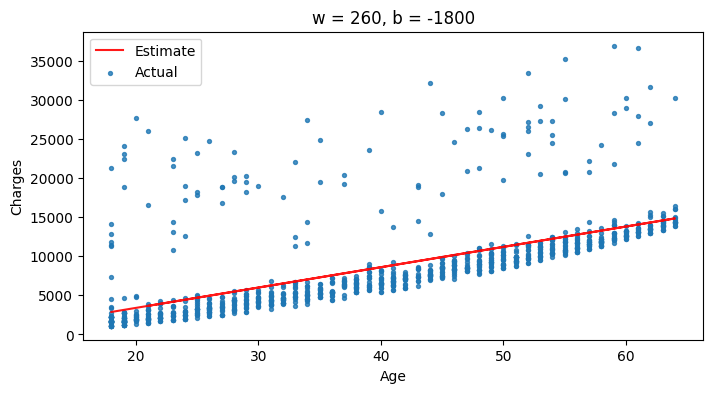

In [ ]:
plt.figure(figsize=(8, 4))
try_parameters(non_smoker_df, 210, 500)
plt.title('w = 210, b = 500')
plt.show()

plt.figure(figsize=(8, 4))
try_parameters(non_smoker_df, 290, -2500)
plt.title('w = 290, b = -2500')
plt.show()

plt.figure(figsize=(8, 4))
try_parameters(non_smoker_df, 260, -1800)
plt.title('w = 260, b = -1800')
plt.show()

**Висновок**: Для некурців із віком витрати загалом зростають, коефіцієнт кореляції становить 0,63. При w = 210 та b = 500 лінія має менший нахил, а при w = 290 та b = -2500 — більший. Третя пара w = 260, b = -1800 візуально краще проходить через основну частину точок. Проте на графіку є люди, витрати яких значно перевищують прогнозовані.

**Завдання 6**: Напишіть фукнцію для обчислення root mean squared error згідно з формулою цієї метрики точності моделі з використанням `numpy`.

Обчисліть RMSE для тих пар пареметрів, які Ви спробували в завданні 5.

Яке найнижче значення втрат ви зможете досягти? Чи можете ви придумати загальну стратегію для знаходження кращих значень $w$ та $b$ методом проб та помилок?

w = 210 b = 500 RMSE = 4743.6
w = 290 b = -2500 RMSE = 4698.85
w = 260 b = -1800 RMSE = 4663.63
Результат першого перебору: 265 -2000 4662.61
Найкраще w: 267
Найкраще b: -2080
Найменша RMSE: 4662.51


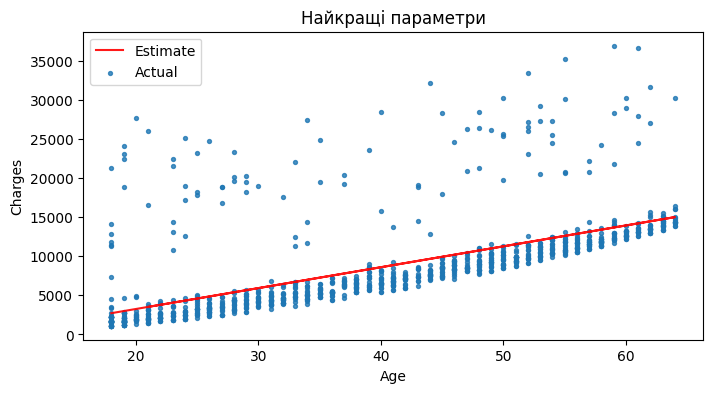

In [ ]:
def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

ages = non_smoker_df['age'].to_numpy()
actual = non_smoker_df['charges'].to_numpy()

for w, b in [(210, 500), (290, -2500), (260, -1800)]:
    predicted = estimate_charges(ages, w, b)
    print('w =', w, 'b =', b, 'RMSE =', round(rmse(actual, predicted), 2))

best_error = float('inf')
best_w = 0
best_b = 0

for w in range(200, 351, 5):
    for b in range(-6000, 1001, 100):
        error = rmse(actual, estimate_charges(ages, w, b))
        if error < best_error:
            best_error = error
            best_w = w
            best_b = b

print('Результат першого перебору:', best_w, best_b, round(best_error, 2))

# Зменшуємо крок біля найкращих параметрів
start_w = best_w
start_b = best_b

for w in range(start_w - 5, start_w + 6):
    for b in range(start_b - 100, start_b + 101, 10):
        error = rmse(actual, estimate_charges(ages, w, b))
        if error < best_error:
            best_error = error
            best_w = w
            best_b = b

print('Найкраще w:', best_w)
print('Найкраще b:', best_b)
print('Найменша RMSE:', round(best_error, 2))

plt.figure(figsize=(8, 4))
try_parameters(non_smoker_df, best_w, best_b)
plt.title('Найкращі параметри')
plt.show()

**Висновок**: Серед трьох початкових пар найменшу RMSE отримали при w = 260 та b = -1800 — 4 663,63. Далі за допомогою двох циклів я перебрав різні значення параметрів і отримав помилку 4 662,61 при w = 265 та b = -2000. Після зменшення кроку перебору найкращим варіантом стали w = 267 та b = -2080, а RMSE зменшилася до 4 662,51. Це найменша помилка серед перевірених варіантів. Загальна стратегія така: спочатку перебрати параметри з великим кроком, а потім поступово зменшувати крок біля найкращих значень.